In [7]:
import pandas as pd

df = pd.read_csv("titanic.csv")
data = df.copy()

# Handle missing values
data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
data["Fare"] = data["Fare"].fillna(data["Fare"].median())

# FamilySize & IsAlone
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

# Title extraction from Name (optional feature from brief)
data["Title"] = data["Name"].str.extract(r",\s*([^\.]*)\.")
rare_titles = data["Title"].value_counts()[data["Title"].value_counts() < 10].index
data["Title"] = data["Title"].replace(rare_titles, "Rare")
data["Title"] = data["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

# Age groups (optional feature from brief)
data["AgeGroup"] = pd.cut(
    data["Age"], bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)

# Encode categoricals
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
data = pd.get_dummies(data, columns=["Embarked", "Title", "AgeGroup"], drop_first=True)

feature_cols = [c for c in data.columns if c not in
                ["PassengerId", "Survived", "Name", "Ticket", "Cabin"]]

X = data[feature_cols]
y = data["Survived"]

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

log_reg = LogisticRegression(max_iter=1000, random_state=42)
rf = RandomForestClassifier(random_state=42)
gb = GradientBoostingClassifier(random_state=42)

log_reg.fit(X_train_scaled, y_train)
rf.fit(X_train, y_train)
gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [11]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, None],
    "min_samples_split": [2, 5]
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42),
                        rf_param_grid, cv=5, scoring="accuracy", n_jobs=-1)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_
print("Best Random Forest params:", rf_grid.best_params_)

gb_param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4]
}
gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=42),
                        gb_param_grid, cv=5, scoring="accuracy", n_jobs=-1)
gb_grid.fit(X_train, y_train)
best_gb = gb_grid.best_estimator_
print("Best Gradient Boosting params:", gb_grid.best_params_)

Best Random Forest params: {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100}
Best Gradient Boosting params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}


In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate(model, X_te, name):
    preds = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-score": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, proba)
    }

results = [
    evaluate(log_reg, X_test_scaled, "Logistic Regression (baseline)"),
    evaluate(best_rf, X_test, "Random Forest (tuned)"),
    evaluate(best_gb, X_test, "Gradient Boosting (tuned)")
]

results_df = pd.DataFrame(results).set_index("Model").round(4)
print(results_df)

                                Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                                         
Logistic Regression (baseline)    0.8492     0.8387  0.7536    0.7939   0.8801
Random Forest (tuned)             0.8268     0.8065  0.7246    0.7634   0.8464
Gradient Boosting (tuned)         0.8101     0.7869  0.6957    0.7385   0.8477


In [14]:
from sklearn.model_selection import cross_val_score

for name, model, X_full in [
        ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42), scaler.fit_transform(X)),
        ("Random Forest", best_rf, X),
        ("Gradient Boosting", best_gb, X)]:
    scores = cross_val_score(model, X_full, y, cv=5, scoring="accuracy")
    print(f"{name:22s} CV Accuracy: {scores.mean():.4f}  (+/- {scores.std():.4f})")

Logistic Regression    CV Accuracy: 0.8238  (+/- 0.0274)
Random Forest          CV Accuracy: 0.8271  (+/- 0.0181)
Gradient Boosting      CV Accuracy: 0.8384  (+/- 0.0199)


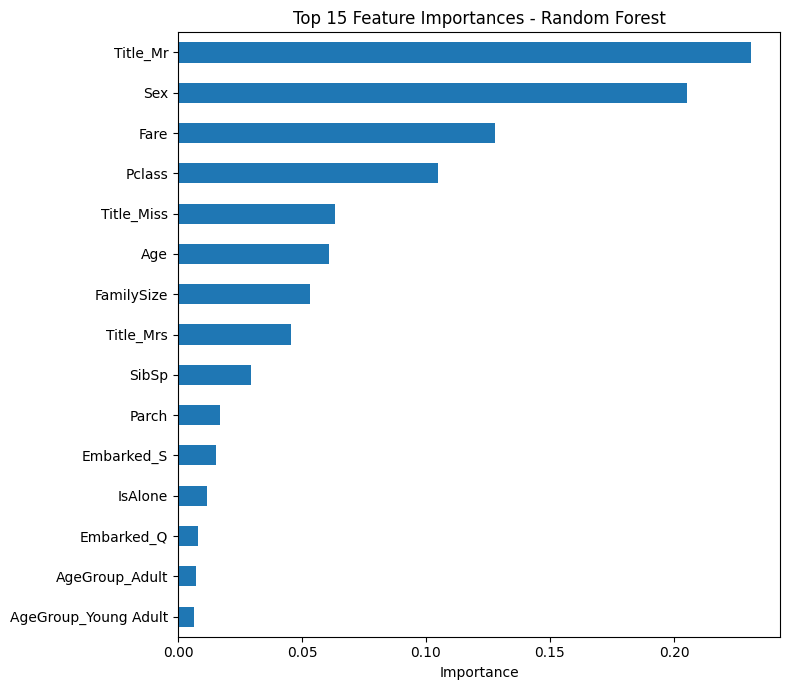

Title_Mr      0.231189
Sex           0.205173
Fare          0.127914
Pclass        0.104651
Title_Miss    0.063372
Age           0.061065
FamilySize    0.053139
Title_Mrs     0.045573
SibSp         0.029523
Parch         0.017087
dtype: float64


In [15]:
import matplotlib.pyplot as plt

importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
importances.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.head(10))

In [16]:
summary = results_df.copy()
summary["CV Mean Accuracy"] = [
    cross_val_score(LogisticRegression(max_iter=1000, random_state=42), scaler.fit_transform(X), y, cv=5).mean(),
    cross_val_score(best_rf, X, y, cv=5).mean(),
    cross_val_score(best_gb, X, y, cv=5).mean()
]

final_choice = summary["CV Mean Accuracy"].idxmax()
print("FINAL MODEL SELECTED:", final_choice)

FINAL MODEL SELECTED: Gradient Boosting (tuned)
